In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Code\ML project ducat\pred_churned.csv")
df.head()

,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,11098-MAD,Female,30,Yes,Madhya Pradesh,0,31,Deal 1,Yes,No,...,Bank Withdrawal,95.10,6683.40,0.00,0,631.72,7315.12,Stayed,Others,Others
1,11114-PUN,Male,51,No,Punjab,5,9,Deal 5,Yes,No,...,Bank Withdrawal,49.15,169.05,0.00,10,122.37,301.42,Churned,Competitor,Competitor had better devices
2,11167-WES,Female,43,Yes,West Bengal,3,28,Deal 1,Yes,Yes,...,Bank Withdrawal,116.05,8297.50,42.57,110,1872.98,10237.90,Stayed,Others,Others
3,11179-MAH,Male,35,No,Maharashtra,10,12,NaN,Yes,No,...,Credit Card,84.40,5969.30,0.00,0,219.39,6188.69,Stayed,Others,Others
4,11180-TAM,Male,75,Yes,Tamil Nadu,12,27,Deal 2,Yes,No,...,Credit Card,72.60,4084.35,0.00,140,332.08,4556.43,Stayed,Others,Others


<h3>Data Exploration</h3>

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_ID                  1000 non-null   object 
 1   Gender                       1000 non-null   object 
 2   Age                          1000 non-null   int64  
 3   Married                      1000 non-null   object 
 4   State                        1000 non-null   object 
 5   Number_of_Referrals          1000 non-null   int64  
 6   Tenure_in_Months             1000 non-null   int64  
 7   Value_Deal                   432 non-null    object 
 8   Phone_Service                1000 non-null   object 
 9   Multiple_Lines               1000 non-null   object 
 10  Internet_Service             1000 non-null   object 
 11  Internet_Type                784 non-null    object 
 12  Online_Security              1000 non-null   object 
 13  Online_Backup      

In [4]:
df.describe()

,Age,Number_of_Referrals,Tenure_in_Months,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,47.446000,7.536000,17.197000,63.967500,2393.859100,2.177470,7.85000,777.477250,3177.008890
std,17.014128,4.656865,10.673055,31.539372,2265.089659,8.296414,27.01124,855.526424,2826.733233
min,18.000000,0.000000,1.000000,-10.000000,19.700000,0.000000,0.00000,0.000000,21.610000
25%,33.000000,3.000000,8.000000,30.575000,566.312500,0.000000,0.00000,115.462500,852.590000
50%,46.000000,8.000000,17.000000,70.750000,1429.350000,0.000000,0.00000,435.000000,2273.895000
75%,61.000000,12.000000,27.000000,90.262500,4029.075000,0.000000,0.00000,1210.305000,5032.612500
max,84.000000,15.000000,36.000000,117.450000,8529.500000,49.230000,150.00000,3564.720000,11795.800000


In [5]:
df.dtypes

Customer_ID                     object
Gender                          object
Age                              int64
Married                         object
State                           object
Number_of_Referrals              int64
Tenure_in_Months                 int64
Value_Deal                      object
Phone_Service                   object
Multiple_Lines                  object
Internet_Service                object
Internet_Type                   object
Online_Security                 object
Online_Backup                   object
Device_Protection_Plan          object
Premium_Support                 object
Streaming_TV                    object
Streaming_Movies                object
Streaming_Music                 object
Unlimited_Data                  object
Contract                        object
Paperless_Billing               object
Payment_Method                  object
Monthly_Charge                 float64
Total_Charges                  float64
Total_Refunds            

In [7]:
# removing customerID
df.drop(["Customer_ID"],axis=1,inplace=True)

In [8]:
df

,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,Internet_Service,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,Female,30,Yes,Madhya Pradesh,0,31,Deal 1,Yes,No,Yes,...,Bank Withdrawal,95.10,6683.40,0.00,0,631.72,7315.12,Stayed,Others,Others
1,Male,51,No,Punjab,5,9,Deal 5,Yes,No,Yes,...,Bank Withdrawal,49.15,169.05,0.00,10,122.37,301.42,Churned,Competitor,Competitor had better devices
2,Female,43,Yes,West Bengal,3,28,Deal 1,Yes,Yes,Yes,...,Bank Withdrawal,116.05,8297.50,42.57,110,1872.98,10237.90,Stayed,Others,Others
3,Male,35,No,Maharashtra,10,12,NaN,Yes,No,Yes,...,Credit Card,84.40,5969.30,0.00,0,219.39,6188.69,Stayed,Others,Others
4,Male,75,Yes,Tamil Nadu,12,27,Deal 2,Yes,No,Yes,...,Credit Card,72.60,4084.35,0.00,140,332.08,4556.43,Stayed,Others,Others
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Male,27,Yes,Tamil Nadu,2,19,NaN,Yes,No,Yes,...,Bank Withdrawal,101.90,1667.25,0.00,120,31.80,1819.05,Stayed,Others,Others
996,Male,40,Yes,Punjab,4,24,Deal 4,Yes,No,No,...,Credit Card,20.60,330.25,0.00,0,535.04,865.29,Stayed,Others,Others
997,Female,27,No,Telangana,1,1,Deal 1,Yes,No,No,...,Credit Card,19.85,1433.80,45.47,0,245.70,1634.03,Stayed,Others,Others
998,Male,33,No,Uttarakhand,5,30,Deal 2,Yes,Yes,Yes,...,Credit Card,80.45,3375.90,0.00,0,727.02,4102.92,Stayed,Others,Others


In [10]:
pd.to_numeric(df.Total_Charges,errors='coerce')

0      6683.40
1       169.05
2      8297.50
3      5969.30
4      4084.35
        ...   
995    1667.25
996     330.25
997    1433.80
998    3375.90
999     447.90
Name: Total_Charges, Length: 1000, dtype: float64

In [12]:
pd.to_numeric(df.Total_Charges,errors='coerce').isnull()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Name: Total_Charges, Length: 1000, dtype: bool

In [14]:
df[pd.to_numeric(df.Total_Charges,errors='coerce').isnull()]

,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,Internet_Service,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason


In [16]:
df[pd.to_numeric(df.Total_Charges,errors='coerce').isnull()].shape

(0, 31)

In [17]:
df1 = df[pd.to_numeric(df.Total_Charges,errors='coerce').isnull() == False]

In [19]:
pd.to_numeric(df1.Total_Charges)

0      6683.40
1       169.05
2      8297.50
3      5969.30
4      4084.35
        ...   
995    1667.25
996     330.25
997    1433.80
998    3375.90
999     447.90
Name: Total_Charges, Length: 1000, dtype: float64

In [20]:
df1.dtypes

Gender                          object
Age                              int64
Married                         object
State                           object
Number_of_Referrals              int64
Tenure_in_Months                 int64
Value_Deal                      object
Phone_Service                   object
Multiple_Lines                  object
Internet_Service                object
Internet_Type                   object
Online_Security                 object
Online_Backup                   object
Device_Protection_Plan          object
Premium_Support                 object
Streaming_TV                    object
Streaming_Movies                object
Streaming_Music                 object
Unlimited_Data                  object
Contract                        object
Paperless_Billing               object
Payment_Method                  object
Monthly_Charge                 float64
Total_Charges                  float64
Total_Refunds                  float64
Total_Extra_Data_Charges 

In [21]:
df1.Total_Charges = pd.to_numeric(df1.Total_Charges)

In [22]:
df1.dtypes

Gender                          object
Age                              int64
Married                         object
State                           object
Number_of_Referrals              int64
Tenure_in_Months                 int64
Value_Deal                      object
Phone_Service                   object
Multiple_Lines                  object
Internet_Service                object
Internet_Type                   object
Online_Security                 object
Online_Backup                   object
Device_Protection_Plan          object
Premium_Support                 object
Streaming_TV                    object
Streaming_Movies                object
Streaming_Music                 object
Unlimited_Data                  object
Contract                        object
Paperless_Billing               object
Payment_Method                  object
Monthly_Charge                 float64
Total_Charges                  float64
Total_Refunds                  float64
Total_Extra_Data_Charges 

<h3>Data Visualization</h3>

In [25]:
# churn w.r.t tenure
tenure_churn_yes = df1[df1.Churn=='Yes'].tenure
tenure_churn_no = df1[df1.Churn=='No'].tenure

plt.hist([tenure_churn_yes,tenure_churn_no],label=["churn_yes","churn_no"],color=['red','green'])
plt.xlabel("tenure")
plt.ylabel("No. of customers")
plt.legend()

AttributeError: 'DataFrame' object has no attribute 'Churn'

In [26]:
# churn w.r.t monthly charges
monthlyCharges_churn_yes = df1[df1.Churn=='Yes'].MonthlyCharges
monthlyCharges_churn_no = df1[df1.Churn=='No'].MonthlyCharges

plt.hist([monthlyCharges_churn_yes,monthlyCharges_churn_no],label=["churn_yes","churn_no"],color=['red','green'])
plt.xlabel("Monthly Charges")
plt.ylabel("No. of customers")
plt.legend()

AttributeError: 'DataFrame' object has no attribute 'Churn'

In [27]:
# print uniques values of each column
def print_unique_values(df1):
    for i in df1.columns:
        if df1[i].dtype=='object':
            print(f"{i}: {df1[i].unique()}")

In [28]:
print_unique_values(df1)

Gender: ['Female' 'Male']
Married: ['Yes' 'No']
State: ['Madhya Pradesh' 'Punjab' 'West Bengal' 'Maharashtra' 'Tamil Nadu'
 'Jammu & Kashmir' 'Uttarakhand' 'Haryana' 'Uttar Pradesh' 'Rajasthan'
 'Andhra Pradesh' 'Karnataka' 'Telangana' 'Kerala' 'Delhi' 'Gujarat'
 'Puducherry' 'Bihar' 'Assam' 'Jharkhand' 'Odisha' 'Chhattisgarh']
Value_Deal: ['Deal 1' 'Deal 5' nan 'Deal 2' 'Deal 3' 'Deal 4']
Phone_Service: ['Yes' 'No']
Multiple_Lines: ['No' 'Yes']
Internet_Service: ['Yes' 'No']
Internet_Type: ['Fiber Optic' 'DSL' 'Cable' nan]
Online_Security: ['Yes' 'No']
Online_Backup: ['Yes' 'No']
Device_Protection_Plan: ['No' 'Yes']
Premium_Support: ['Yes' 'No']
Streaming_TV: ['No' 'Yes']
Streaming_Movies: ['Yes' 'No']
Streaming_Music: ['Yes' 'No']
Unlimited_Data: ['Yes' 'No']
Contract: ['Two Year' 'Month-to-Month' 'One Year']
Paperless_Billing: ['No' 'Yes']
Payment_Method: ['Bank Withdrawal' 'Credit Card' 'Mailed Check']
Customer_Status: ['Stayed' 'Churned']
Churn_Category: ['Others' 'Competitor' 'Pr

In [30]:
print_unique_values(df1)

Gender: ['Female' 'Male']
Married: ['Yes' 'No']
State: ['Madhya Pradesh' 'Punjab' 'West Bengal' 'Maharashtra' 'Tamil Nadu'
 'Jammu & Kashmir' 'Uttarakhand' 'Haryana' 'Uttar Pradesh' 'Rajasthan'
 'Andhra Pradesh' 'Karnataka' 'Telangana' 'Kerala' 'Delhi' 'Gujarat'
 'Puducherry' 'Bihar' 'Assam' 'Jharkhand' 'Odisha' 'Chhattisgarh']
Value_Deal: ['Deal 1' 'Deal 5' nan 'Deal 2' 'Deal 3' 'Deal 4']
Phone_Service: ['Yes' 'No']
Multiple_Lines: ['No' 'Yes']
Internet_Service: ['Yes' 'No']
Internet_Type: ['Fiber Optic' 'DSL' 'Cable' nan]
Online_Security: ['Yes' 'No']
Online_Backup: ['Yes' 'No']
Device_Protection_Plan: ['No' 'Yes']
Premium_Support: ['Yes' 'No']
Streaming_TV: ['No' 'Yes']
Streaming_Movies: ['Yes' 'No']
Streaming_Music: ['Yes' 'No']
Unlimited_Data: ['Yes' 'No']
Contract: ['Two Year' 'Month-to-Month' 'One Year']
Paperless_Billing: ['No' 'Yes']
Payment_Method: ['Bank Withdrawal' 'Credit Card' 'Mailed Check']
Customer_Status: ['Stayed' 'Churned']
Churn_Category: ['Others' 'Competitor' 'Pr

In [31]:
df2 = pd.get_dummies(df1,columns=["InternetService","Contract","PaymentMethod"])

KeyError: "['InternetService', 'PaymentMethod'] not in index"

In [27]:
df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,Female,0,Yes,No,1,No,No,No,Yes,No,...,1,0,0,1,0,0,0,0,1,0
1,Male,0,No,No,34,Yes,No,Yes,No,Yes,...,1,0,0,0,1,0,0,0,0,1
2,Male,0,No,No,2,Yes,No,Yes,Yes,No,...,1,0,0,1,0,0,0,0,0,1
3,Male,0,No,No,45,No,No,Yes,No,Yes,...,1,0,0,0,1,0,1,0,0,0
4,Female,0,No,No,2,Yes,No,No,No,No,...,0,1,0,1,0,0,0,0,1,0


In [28]:
yes_no_cols = ['Partner','Dependents','PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
               'StreamingTV','StreamingMovies','PaperlessBilling','Churn']
for i in yes_no_cols:
    df2[i].replace({"Yes":1,"No":0},inplace=True)

In [29]:
df2['gender'].replace({"Female":1,"Male":0},inplace=True)

In [30]:
df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,0,1,0,1,0,0,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,0,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,0,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,0,0,0,0,45,0,0,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,1,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


In [31]:
for i in df2:
    print(f"{i}: {df2[i].unique()}")

gender: [1 0]
SeniorCitizen: [0 1]
Partner: [1 0]
Dependents: [0 1]
tenure: [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26 39]
PhoneService: [0 1]
MultipleLines: [0 1]
OnlineSecurity: [0 1]
OnlineBackup: [1 0]
DeviceProtection: [0 1]
TechSupport: [0 1]
StreamingTV: [0 1]
StreamingMovies: [0 1]
PaperlessBilling: [1 0]
MonthlyCharges: [29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
TotalCharges: [  29.85 1889.5   108.15 ...  346.45  306.6  6844.5 ]
Churn: [0 1]
InternetService_DSL: [1 0]
InternetService_Fiber optic: [0 1]
InternetService_No: [0 1]
Contract_Month-to-month: [1 0]
Contract_One year: [0 1]
Contract_Two year: [0 1]
PaymentMethod_Bank transfer (automatic): [0 1]
PaymentMethod_Credit card (automatic): [0 1]
PaymentMethod_Electronic check: [1 0]
PaymentMethod_Mailed check: [0 1]


In [32]:
df2.dtypes

gender                                       int64
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                       int64
PhoneService                                 int64
MultipleLines                                int64
OnlineSecurity                               int64
OnlineBackup                                 int64
DeviceProtection                             int64
TechSupport                                  int64
StreamingTV                                  int64
StreamingMovies                              int64
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                               float64
Churn                                        int64
InternetService_DSL                          uint8
InternetService_Fiber optic                  uint8
InternetService_No             

<h3>Scaling</h3>

In [33]:
# minmax scaling brings the values of the reamining 2 numerical columns to a range of 0-1 as the other column values are 0 or 1
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
cols_to_scale = ['tenure','TotalCharges','MonthlyCharges']
df2[cols_to_scale] = scaler.fit_transform(df2[cols_to_scale])

In [34]:
for i in df2:
    print(f"{i}: {df2[i].unique()}")

gender: [1 0]
SeniorCitizen: [0 1]
Partner: [1 0]
Dependents: [0 1]
tenure: [0.         0.46478873 0.01408451 0.61971831 0.09859155 0.29577465
 0.12676056 0.38028169 0.85915493 0.16901408 0.21126761 0.8028169
 0.67605634 0.33802817 0.95774648 0.71830986 0.98591549 0.28169014
 0.15492958 0.4084507  0.64788732 1.         0.22535211 0.36619718
 0.05633803 0.63380282 0.14084507 0.97183099 0.87323944 0.5915493
 0.1971831  0.83098592 0.23943662 0.91549296 0.11267606 0.02816901
 0.42253521 0.69014085 0.88732394 0.77464789 0.08450704 0.57746479
 0.47887324 0.66197183 0.3943662  0.90140845 0.52112676 0.94366197
 0.43661972 0.76056338 0.50704225 0.49295775 0.56338028 0.07042254
 0.04225352 0.45070423 0.92957746 0.30985915 0.78873239 0.84507042
 0.18309859 0.26760563 0.73239437 0.54929577 0.81690141 0.32394366
 0.6056338  0.25352113 0.74647887 0.70422535 0.35211268 0.53521127]
PhoneService: [0 1]
MultipleLines: [0 1]
OnlineSecurity: [0 1]
OnlineBackup: [1 0]
DeviceProtection: [0 1]
TechSupport: [

<h3>Model Building</h3>

In [35]:
X = df2.drop(['Churn'],axis=1)
y = df2.Churn

In [36]:
from sklearn.model_selection import train_test_split
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.2,random_state=21)

In [37]:
Xtrain.shape

(5625, 26)

In [38]:
Xtest.shape

(1407, 26)

In [39]:
from keras.models import Sequential
from keras.layers import Dense,InputLayer
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6345 - loss: 0.5977
Epoch 2/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7892 - loss: 0.4347
Epoch 3/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8021 - loss: 0.4202
Epoch 4/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8017 - loss: 0.4157
Epoch 5/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8096 - loss: 0.4030
Epoch 6/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8065 - loss: 0.4166
Epoch 7/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8181 - loss: 0.3931
Epoch 8/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8088 - loss: 0.4076
Epoch 9/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8065 - loss: 0.4096
Epoch 10/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8040 - loss: 0.4091
Epoch 11/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8120 - loss: 0.4023
Epoch 12/100
176/176 ━━━━━━━━━━━━━━━━━━━━

In [40]:
model.evaluate(Xtest,ytest)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7745 - loss: 0.5021


[0.48639389872550964, 0.7761194109916687]

In [41]:
yp = model.predict(Xtest)
yp

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[0.98687047],
       [0.41550398],
       [0.11019586],
       ...,
       [0.4145826 ],
       [0.34860483],
       [0.5734485 ]], dtype=float32)

In [42]:
ypred = []
for i in yp:
    if i >= 0.5:
        ypred.append(1)
    else:
        ypred.append(0)

In [43]:
ypred[:5]

[1, 0, 0, 0, 1]

In [44]:
from sklearn.metrics import classification_report
print(classification_report(ytest,ypred))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1007
           1       0.63      0.51      0.57       400

    accuracy                           0.78      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.77      0.78      0.77      1407



Text(50.722222222222214, 0.5, 'True')

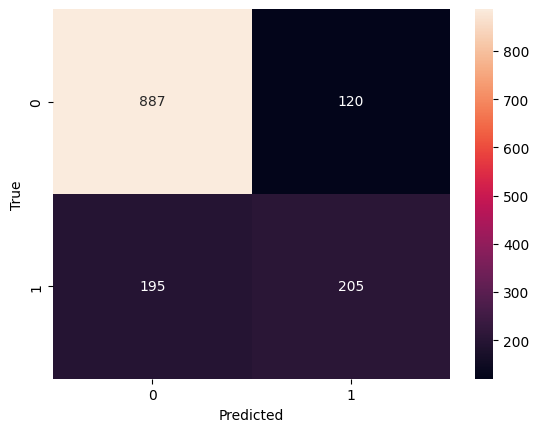

In [45]:
cm = tf.math.confusion_matrix(labels=ytest, predictions=ypred)
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("True")

In [46]:
# accuracy
(920+178)/(920+222+178+87)

0.7803837953091685

In [47]:
# precision of getting 1
178/(178+87)

0.6716981132075471

In [48]:
# recalll of getting 1
178/(178+222)

0.445

# Part 21: Handling imbalance in the dataset

In [49]:
df2["Churn"].value_counts()
# imbalance in the dataset

0    5163
1    1869
Name: Churn, dtype: int64

<h4>accuracy does not matter when there is imbalance in the dataset and the imbalance can be indicated using F1-score or precision or recall of the two classes</h4>

<h3>method1: Random Undersampling</h3>

In [50]:
df2.Churn.value_counts()

0    5163
1    1869
Name: Churn, dtype: int64

In [51]:
count_class_0,count_class_1 = df2.Churn.value_counts()
count_class_0, count_class_1

(5163, 1869)

In [52]:
df_class_0 = df2[df2["Churn"] == 0]
df_class_1 = df2[df2["Churn"] == 1]

In [53]:
df_class_0.shape

(5163, 27)

In [54]:
df_class_0_under = df_class_0.sample(count_class_1)

In [55]:
df_under = pd.concat([df_class_0_under,df_class_1],axis=0)

In [56]:
df_under.Churn.value_counts()

0    1869
1    1869
Name: Churn, dtype: int64

In [57]:
df_under.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3738 entries, 3648 to 7041
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   3738 non-null   int64  
 1   SeniorCitizen                            3738 non-null   int64  
 2   Partner                                  3738 non-null   int64  
 3   Dependents                               3738 non-null   int64  
 4   tenure                                   3738 non-null   float64
 5   PhoneService                             3738 non-null   int64  
 6   MultipleLines                            3738 non-null   int64  
 7   OnlineSecurity                           3738 non-null   int64  
 8   OnlineBackup                             3738 non-null   int64  
 9   DeviceProtection                         3738 non-null   int64  
 10  TechSupport                              3738

In [58]:
X = df_under.drop(["Churn"],axis=1)
y = df_under["Churn"]

In [59]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.2,random_state=5,stratify=y)
# stratifying y will help in ensuring an equal class distribution in both test and training data

In [60]:
ytrain.value_counts()

1    1495
0    1495
Name: Churn, dtype: int64

In [61]:
ytest.value_counts()

0    374
1    374
Name: Churn, dtype: int64

In [62]:
from keras.models import Sequential
from keras.layers import Dense,InputLayer
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6007 - loss: 0.6689
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7395 - loss: 0.5245
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7560 - loss: 0.4967
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7632 - loss: 0.4942
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7691 - loss: 0.4802
Epoch 6/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7715 - loss: 0.4761
Epoch 7/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7692 - loss: 0.4835
Epoch 8/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7633 - loss: 0.4750
Epoch 9/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7763 - loss: 0.4599
Epoch 10/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7664 - loss: 0.4717
Epoch 11/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7606 - loss: 0.4817
Epoch 12/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

In [63]:
ypred = model.predict(Xtest)
ypred = np.round(ypred)
ypred[:5]

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[0.],
       [1.],
       [0.],
       [1.],
       [1.]], dtype=float32)

In [64]:
ytest[:5]

2515    0
3000    1
69      0
4124    0
2629    1
Name: Churn, dtype: int64

In [65]:
print(classification_report(ytest,ypred))

              precision    recall  f1-score   support

           0       0.75      0.72      0.74       374
           1       0.73      0.76      0.75       374

    accuracy                           0.74       748
   macro avg       0.74      0.74      0.74       748
weighted avg       0.74      0.74      0.74       748



<h3>method2: Random Oversampling</h3>

In [66]:
df_class_1_over = df_class_1.sample(count_class_0,replace=True)
df_over = pd.concat([df_class_1_over,df_class_0],axis=0)
# oversamples class one sampling by creating duplicates

In [67]:
df_over.Churn.value_counts()

1    5163
0    5163
Name: Churn, dtype: int64

In [68]:
X = df_over.drop(["Churn"],axis=1)
y = df_over["Churn"]

In [69]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.2,random_state=5,stratify=y)
# stratifying y will help in ensuring an equal class distribution in both test and training data

In [70]:
ytrain.value_counts()

0    4130
1    4130
Name: Churn, dtype: int64

In [71]:
ytest.value_counts()

1    1033
0    1033
Name: Churn, dtype: int64

In [72]:
from keras.models import Sequential
from keras.layers import Dense,InputLayer
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7028 - loss: 0.5811
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7515 - loss: 0.4981
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7645 - loss: 0.4836
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7678 - loss: 0.4741
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7683 - loss: 0.4774
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7611 - loss: 0.4787
Epoch 7/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7658 - loss: 0.4789
Epoch 8/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7674 - loss: 0.4671
Epoch 9/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7884 - loss: 0.4576
Epoch 10/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7761 - loss: 0.4647
Epoch 11/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7749 - loss: 0.4584
Epoch 12/100
259/259 ━━━━━━━━━━━━━━━━━━━━

In [73]:
ypred = model.predict(Xtest)
ypred = np.round(ypred)
ypred[:5]

65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


array([[1.],
       [1.],
       [1.],
       [0.],
       [0.]], dtype=float32)

In [74]:
ytest[:5]

5300    1
5306    1
5475    1
3372    0
1254    0
Name: Churn, dtype: int64

In [75]:
print(classification_report(ytest,ypred))

              precision    recall  f1-score   support

           0       0.86      0.73      0.79      1033
           1       0.76      0.88      0.82      1033

    accuracy                           0.80      2066
   macro avg       0.81      0.80      0.80      2066
weighted avg       0.81      0.80      0.80      2066



<h3>method3: SMOTE</h3>

In [79]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy="minority")

X_sm,y_sm = smote.fit_resample(X,y)
y_sm.value_counts()

1    5163
0    5163
Name: Churn, dtype: int64

In [89]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X_sm,y_sm,test_size=0.20,random_state=2,stratify=y_sm)

In [90]:
ytrain.value_counts()

0    4130
1    4130
Name: Churn, dtype: int64

In [91]:
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6930 - loss: 0.5822
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7587 - loss: 0.4939
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7621 - loss: 0.4879
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7659 - loss: 0.4843
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7807 - loss: 0.4646
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7775 - loss: 0.4641
Epoch 7/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7727 - loss: 0.4708
Epoch 8/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7675 - loss: 0.4739
Epoch 9/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7745 - loss: 0.4647
Epoch 10/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7829 - loss: 0.4565
Epoch 11/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7854 - loss: 0.4552
Epoch 12/100
259/259 ━━━━━━━━━━━━━━━━━━━━

In [92]:
ypred = model.predict(Xtest)
ypred = np.round(ypred)
ypred[:5]

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[1.],
       [1.],
       [0.],
       [1.],
       [0.]], dtype=float32)

In [93]:
print(classification_report(ytest,ypred))

              precision    recall  f1-score   support

           0       0.85      0.76      0.81      1033
           1       0.78      0.87      0.82      1033

    accuracy                           0.82      2066
   macro avg       0.82      0.82      0.82      2066
weighted avg       0.82      0.82      0.82      2066



<h3>method4: Ensemble</h3>

In [94]:
df2.Churn.value_counts()

0    5163
1    1869
Name: Churn, dtype: int64

In [100]:
X = df2.drop(["Churn"],axis=1)
y = df2["Churn"]

In [101]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.20,random_state=2,stratify=y)

In [102]:
ytrain.value_counts()

0    4130
1    1495
Name: Churn, dtype: int64

In [105]:
4130/1495
# class1 = 1/3 times of class 0 thus we will be dividing the class0 into 3 sets

2.762541806020067

In [106]:
df3 = Xtrain.copy()
df3["Churn"] = ytrain

In [108]:
df3_class0 = df3[df3["Churn"] == 0]
df3_class1 = df3[df3.Churn == 1]

In [110]:
def train_ensemble(df_minority,df_majority,start,end):
    df_train = pd.concat([df_majority[start:end],df_minority],axis=0)
    Xtrain = df_train.drop(["Churn"],axis=1)
    ytrain = df_train["Churn"]
    return Xtrain,ytrain

In [111]:
Xtrain,ytrain = train_ensemble(df3_class1,df3_class0,0,1495)

In [112]:
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6146 - loss: 0.6538
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7409 - loss: 0.5246
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7602 - loss: 0.4958
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7695 - loss: 0.4874
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7479 - loss: 0.5029
Epoch 6/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7590 - loss: 0.4852
Epoch 7/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7699 - loss: 0.4777
Epoch 8/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7651 - loss: 0.4809
Epoch 9/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7614 - loss: 0.4824
Epoch 10/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7641 - loss: 0.4813
Epoch 11/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7556 - loss: 0.4801
Epoch 12/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

In [121]:
ypred1 = model.predict(Xtest)
ypred1 = np.round(ypred1)
ypred1[:5]

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


array([[0.],
       [1.],
       [1.],
       [1.],
       [1.]], dtype=float32)

In [122]:
ypred1.shape

(1407, 1)

In [123]:
ytest.shape

(1407,)

In [124]:
print(classification_report(ytest,ypred1))

              precision    recall  f1-score   support

           0       0.90      0.69      0.78      1033
           1       0.48      0.79      0.60       374

    accuracy                           0.72      1407
   macro avg       0.69      0.74      0.69      1407
weighted avg       0.79      0.72      0.73      1407



In [125]:
2*1495

2990

In [126]:
# sample 2
Xtrain,ytrain = train_ensemble(df3_class1,df3_class0,1495,2990)

In [127]:
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5862 - loss: 0.6626
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7320 - loss: 0.5360
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7340 - loss: 0.5213
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7596 - loss: 0.5068
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7575 - loss: 0.5035
Epoch 6/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7597 - loss: 0.4924
Epoch 7/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7557 - loss: 0.4918
Epoch 8/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7614 - loss: 0.4844
Epoch 9/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7643 - loss: 0.4837
Epoch 10/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7648 - loss: 0.4900
Epoch 11/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7603 - loss: 0.4810
Epoch 12/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

In [128]:
ypred2 = model.predict(Xtest)
ypred2 = np.round(ypred2)
ypred2[:5]

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


array([[0.],
       [1.],
       [1.],
       [1.],
       [1.]], dtype=float32)

In [129]:
ypred2.shape

(1407, 1)

In [130]:
print(classification_report(ytest,ypred2))

              precision    recall  f1-score   support

           0       0.87      0.79      0.83      1033
           1       0.54      0.67      0.60       374

    accuracy                           0.76      1407
   macro avg       0.70      0.73      0.71      1407
weighted avg       0.78      0.76      0.77      1407



In [133]:
# sample 3
Xtrain,ytrain = train_ensemble(df3_class1,df3_class0,2990,4130)

In [134]:
model = Sequential([
    InputLayer(shape=(26,)),
    Dense(26,activation='relu'),
    Dense(30,activation='relu'),
    Dense(1,activation='sigmoid')])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy']
             )
model.fit(Xtrain,ytrain,epochs=100)

Epoch 1/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6137 - loss: 0.6536
Epoch 2/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7552 - loss: 0.5069
Epoch 3/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7598 - loss: 0.4955
Epoch 4/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7780 - loss: 0.4657
Epoch 5/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7811 - loss: 0.4534
Epoch 6/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7614 - loss: 0.4736
Epoch 7/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7660 - loss: 0.4783
Epoch 8/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7843 - loss: 0.4628
Epoch 9/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7697 - loss: 0.4687
Epoch 10/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7821 - loss: 0.4618
Epoch 11/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7774 - loss: 0.4587
Epoch 12/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy:

In [135]:
ypred3 = np.round(model.predict(Xtest))
ypred3.shape

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


(1407, 1)

In [136]:
print(classification_report(ytest,ypred3))

              precision    recall  f1-score   support

           0       0.92      0.64      0.75      1033
           1       0.46      0.84      0.60       374

    accuracy                           0.69      1407
   macro avg       0.69      0.74      0.67      1407
weighted avg       0.80      0.69      0.71      1407



<h3>voting majority</h3>
Suppose
vote1 = 0,
vote2 = 1,
vote3 = 1,
then outcome is one so if no. of ones > 1 then the output will be 1

In [137]:
y_pred_final = ypred1.copy()
for i in range(len(ypred1)):
    n_ones = ypred1[i] + ypred2[i] + ypred3[i]
    if n_ones > 1:
        y_pred_final[i] = 1
    else:
        y_pred_final[i] = 0

In [139]:
print(classification_report(ytest,y_pred_final))
# not that good but we can run different experiments with these 4 sampling techniques to find out which one gives the best result

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1033
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.74      0.75      1407

